In [16]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit
from scipy.stats import chi2, lognorm

# successful fits: 
# LV4 + aSyn WT                 
# LV4 + aSyn E61V
# LV4 + aSyn A124T
# LV4 + aSyn E46K
# POPG + aSyn WT
# POPG + 25uM aSyn variants
# DOPC/GM1 + aSyn WT
# DOPC/GM1 + 25uM aSyn variants
# DOPC/DOPS + aSyn WT
# DOPC/DOPS + 25uM aSyn variants

# Observables:
# 1. Median radius
# 2. Fraction of P(r) shifted to higher values (integral)

# presentation: 
# aSyn conc. against R/R0 ==> different lipid conditions
# aSyn conc. against fraction of P(r) shifted to higher values (integral) ==> different lipid conditions


In [17]:
# collect samples in sorted way
LV4 = {
    "name": "LV4",
    "pure": "BII_S9",
    "WT": [
        "BIV_S1",
        # "BIV_S2",
        # "BIV_S3",
        "BIV_S4",
        "BIV_S5",
        "BIV_S6",
        "BIV_S7",
        "BIV_S8",
        "BIV_S9",
        "BIV_S10"],
    "A124T": [
        "BIV_S21",
        "BIV_S22",
        "BIV_S23",
        "BIV_S24",
        "BIV_S25",
        "BIV_S26",
        "BIV_S27",
        "BIV_S28",
        "BIV_S29",
        "BIV_S30",],
    "E61V": [
        "BIV_S11",
        "BIV_S12",
        "BIV_S13",
        "BIV_S14",
        "BIV_S15",
        "BIV_S16",
        "BIV_S17",
        "BIV_S18",
        "BIV_S19",
        "BIV_S20",],
    "E46K": [
        "BIV_S31",
        "BIV_S32",
        "BIV_S33",
        "BIV_S34",
        "BIV_S35",
        "BIV_S36",
        "BIV_S37",
        "BIV_S38",
        "BIV_S39",
        "BIV_S40",],
}
DOPC_GM1 = {
    "name": "DOPC/GM1 (8/2)",
    "pure": "BIX_S2",
    "WT": ["BVI_S1",
           "BVI_S2",
           "BVI_S3",
           "BVI_S4",
           "BVI_S5",
           "BVI_S6",
           "BVI_S7"],
    "A124T": ["BVI_S9"],
    "E61V": ["BVI_S8"],
    "E46K": ["BVI_S10"],
}
POPG = {
    "name": "POPG",
    "pure": "BIX_S1",
    "WT": ["BVI_S11",
           "BVI_S12",
        #    "BVI_S13", BAD BACKGROUND SUBTRACTION
           "BVI_S14",
           "BVI_S15",
           "BVI_S16",
           "BVI_S17"],
    "A124T": ["BVI_S19"],
    "E61V": ["BVI_S18"],
    "E46K": ["BVI_S20"],
}
PCPS = {
    "name": "DOPC/DOPS (8/2)",
    "pure": "BII_S11",
    "WT": [
        "BIX_S15", #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
        "BIX_S16", #: "15 mM DOPC/DOPS  (8/2) + 9 μM aSynWT",
        "BIX_S17", #: "15 mM DOPC/DOPS (8/2) + 15 μM aSynWT",
        "BIX_S18", #: "15 mM DOPC/DOPS (8/2) + 25 μM aSynWT",
        "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",
        # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
        "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
        ],
    "A124T": ["BVI_S9"],
    "E61V": ["BVI_S8"],
    "E46K": ["BVI_S10"],
}

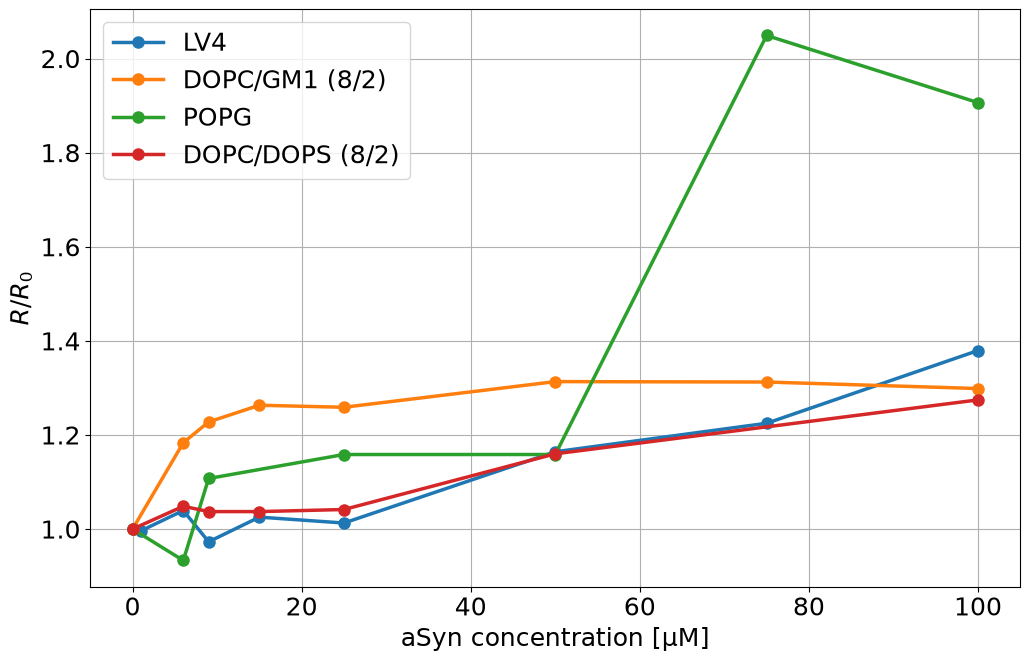

In [18]:
# Make aSyn-R/R0 plot for WT (sph. asym. lognormal)
# R0 is the median of the lognormal size distribution
succesful_series = [LV4, DOPC_GM1, POPG, PCPS]
f = plt.figure(figsize=(12, 7.5))
for series in succesful_series:
    aSyn_conc = [0]
    R_over_R0 = [1]
    if series == DOPC_GM1:
        fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    else:
        fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0 = BM29.best_fits[series["pure"]][fit_function_name][1][0]
    for sample in series["WT"]:
        # print(sample)
        R = BM29.best_fits[sample][fit_function_name][1][0]
        aSyn_conc.append(BM29.concentrations[sample])
        R_over_R0.append(R/R0)
    plt.plot(aSyn_conc, R_over_R0, label=series["name"], lw=2.5, marker='o', markersize=8)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$R/R_0$")
plt.grid()
plt.legend()
plt.show()


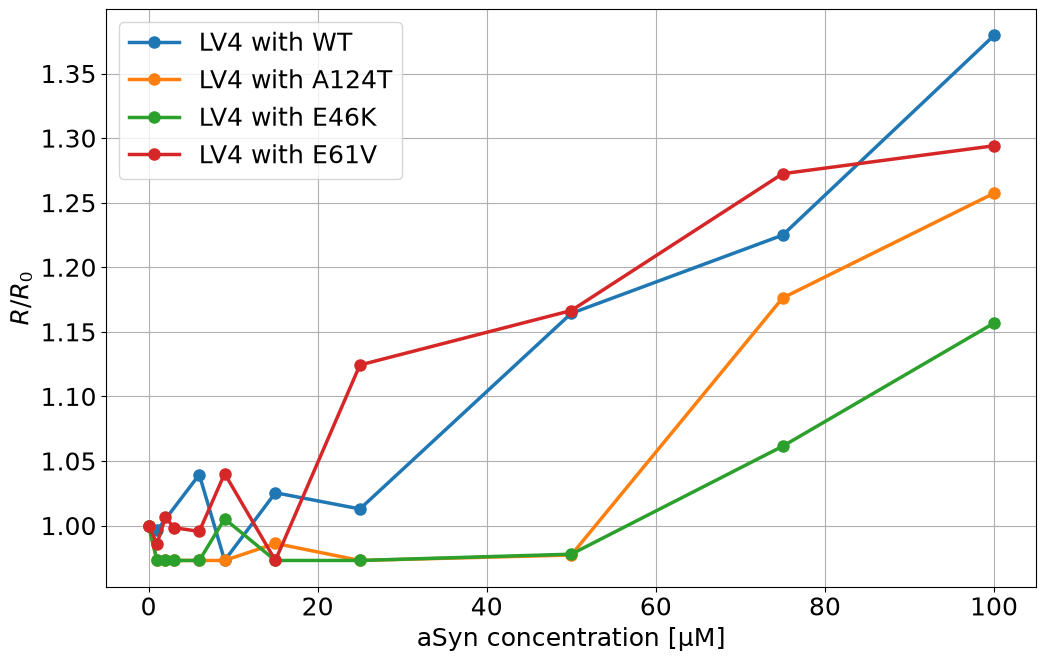

In [19]:
# LV4 + variants, aSyn-R/R0 plot
variants = ["WT", "A124T", "E46K", "E61V"]
f = plt.figure(figsize=(12, 7.5))
for variant in variants:
    aSyn_conc = [0]
    R_over_R0 = [1]
    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0 = BM29.best_fits[LV4["pure"]][fit_function_name][1][0]
    for sample in LV4[variant]:
        # print(sample)
        R = BM29.best_fits[sample][fit_function_name][1][0]
        aSyn_conc.append(BM29.concentrations[sample])
        R_over_R0.append(R/R0)
    plt.plot(aSyn_conc, R_over_R0, label=f"LV4 with {variant}", lw=2.5, marker='o', markersize=8)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$R/R_0$")
plt.grid()
plt.legend()
plt.show()

BIV_S1
BIV_S4
BIV_S5
BIV_S6
BIV_S7
BIV_S8
BIV_S9
BIV_S10
BVI_S1
BVI_S2
BVI_S3
BVI_S4
BVI_S5
BVI_S6
BVI_S7
BVI_S11
BVI_S12
BVI_S14
BVI_S15
BVI_S16
BVI_S17
BIX_S15
BIX_S16
BIX_S17
BIX_S18
BIX_S19
BVII_S5


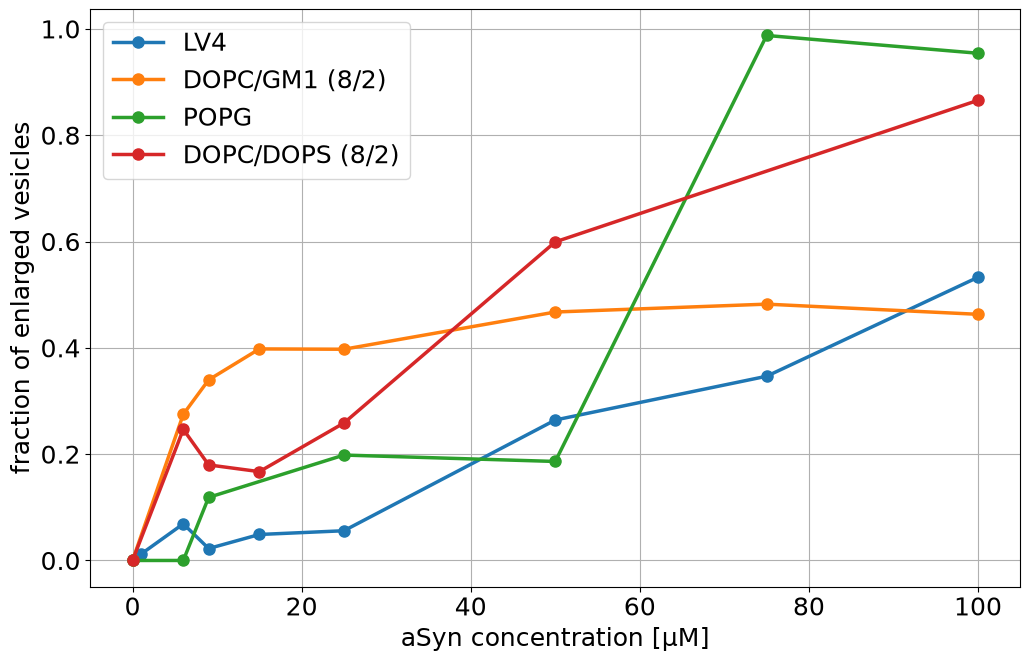

In [33]:
# aSyn - fraction of enlarged vesicles plot for WT (sph. asym. lognormal)
# R0 is the median of the lognormal size distribution
def lognorm_polydisp_enlargement(P_R0, P_R, R0, R, R_interval):
    intersection_index = []
    for i in range(len(P_R)):
        pos_cross_condition = (P_R0[i-1] > P_R[i-1]) and (P_R0[i] < P_R[i])
        radius_condition    = (np.abs(R_interval[i] - R0) < 12) 
        if pos_cross_condition and radius_condition:
            intersection_index.append(i)
    if len(intersection_index) == 0:
        print("WARNING: No intersections ...")
        integral_diff = 0
        return integral_diff
    elif len(intersection_index) != 1:
        print("WARNING: Multiple intersections ...")
    int_P_R = np.trapezoid(P_R[intersection_index[0]:], R_interval[intersection_index[0]:])
    int_P_R0 = np.trapezoid(P_R0[intersection_index[0]:], R_interval[intersection_index[0]:])
    integral_diff_larger = int_P_R - int_P_R0
    int_P_R = np.trapezoid(P_R[:intersection_index[0]], R_interval[:intersection_index[0]])
    int_P_R0 = np.trapezoid(P_R0[:intersection_index[0]], R_interval[:intersection_index[0]])
    integral_diff_smaller = int_P_R0 - int_P_R
    if integral_diff_larger < 0 or integral_diff_smaller < 0:
        print("WARNING: Unexpected curve trajectory ...")
    enlarged_fraction = integral_diff_smaller + integral_diff_larger
    return enlarged_fraction

succesful_series = [LV4, DOPC_GM1, POPG, PCPS]
f = plt.figure(figsize=(12, 7.5))
R_interval = np.linspace(0, R0 + 50, 1000)
for series in succesful_series:
    aSyn_conc = [0]
    frac_enlarged = [0]
    if series == DOPC_GM1:
        fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    else:
        fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0, sigma0 = BM29.best_fits[series["pure"]][fit_function_name][1][0:2]
    P_R0 = lognorm.pdf(R_interval, s=sigma0, scale=R0)
    for sample in series["WT"]:
        print(sample)
        R, sigma = BM29.best_fits[sample][fit_function_name][1][0:2]
        aSyn_conc.append(BM29.concentrations[sample])
        P_R = lognorm.pdf(R_interval, s=sigma, scale=R)
        integral_diff = lognorm_polydisp_enlargement(P_R0, P_R, R0, R, R_interval)
        frac_enlarged.append(integral_diff)
    plt.plot(aSyn_conc, frac_enlarged, label=series["name"], lw=2.5, marker='o', markersize=8)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("fraction of enlarged vesicles")
plt.grid()
plt.legend()
plt.show()

BIV_S1
BIV_S4
BIV_S5
BIV_S6
BIV_S7
BIV_S8
BIV_S9
BIV_S10
BIV_S21
BIV_S22
BIV_S23
BIV_S24
BIV_S25
BIV_S26
BIV_S27
BIV_S28
BIV_S29
BIV_S30
BIV_S31
BIV_S32
BIV_S33
BIV_S34
BIV_S35
BIV_S36
BIV_S37
BIV_S38
BIV_S39
BIV_S40
BIV_S11
BIV_S12
BIV_S13
BIV_S14
BIV_S15
BIV_S16
BIV_S17
BIV_S18
BIV_S19
BIV_S20


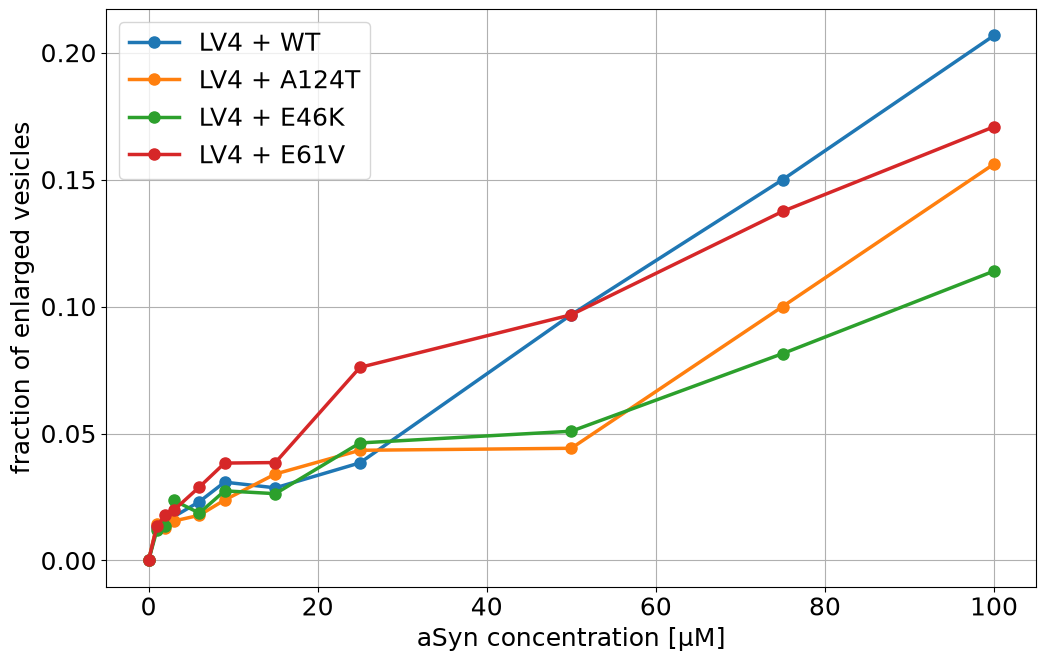

In [ ]:
# aSyn - fraction of enlarged vesicles plot for variants (sph. asym. lognormal)
variants = ["WT", "A124T", "E46K", "E61V"]
f = plt.figure(figsize=(12, 7.5))
R_interval = np.linspace(0, R0 + 50, 1000)
for variant in variants:
    aSyn_conc = [0]
    frac_enlarged = [0]
    fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0, sigma0 = BM29.best_fits[series["pure"]][fit_function_name][1][0:2]
    P_R0 = lognorm.pdf(R_interval, s=sigma0, scale=R0)
    for sample in LV4[variant]:
        print(sample)
        R, sigma = BM29.best_fits[sample][fit_function_name][1][0:2]
        aSyn_conc.append(BM29.concentrations[sample])
        P_R = lognorm.pdf(R_interval, s=sigma, scale=R)
        integral_diff = lognorm_polydisp_enlargement(P_R0, P_R, R0, R, R_interval)
        frac_enlarged.append(integral_diff)
    plt.plot(aSyn_conc, frac_enlarged, label=f"LV4 + {variant}", lw=2.5, marker='o', markersize=8)
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("fraction of enlarged vesicles")
plt.grid()
plt.legend()
plt.show()